Buisness Question “Are customers coming back to make purchases after their first purchase?”

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv(
    "../data/processed/online_retail_clean.csv",
    parse_dates=["InvoiceDate"]
)

In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 392692 entries, 0 to 392691
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  int64         
 1   StockCode    392692 non-null  str           
 2   Description  392692 non-null  str           
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[us]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  int64         
 7   Country      392692 non-null  str           
 8   TotalPrice   392692 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(3), str(3)
memory usage: 43.8 MB


In [6]:
df.describe()

,InvoiceNo,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalPrice
count,392692.000000,392692.000000,392692,392692.000000,392692.000000,392692.000000
mean,560590.875047,13.119702,2011-07-10 19:13:07.771892,3.125914,15287.843865,22.631500
min,536365.000000,1.000000,2010-12-01 08:26:00,0.001000,12346.000000,0.001000
25%,549234.000000,2.000000,2011-04-07 11:12:00,1.250000,13955.000000,4.950000
50%,561874.000000,6.000000,2011-07-31 12:02:00,1.950000,15150.000000,12.450000
75%,572061.000000,12.000000,2011-10-20 12:53:00,3.750000,16791.000000,19.800000
max,581587.000000,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000,168469.600000
std,13087.063759,180.492832,NaN,22.241836,1713.539549,311.099224


In [ ]:
df["InvoiceDate"].h

0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[us]

In [8]:
df["InvoiceMonth"] = df["InvoiceDate"].dt.to_period("M")

In [9]:
df["InvoiceMonth"]

0         2010-12
1         2010-12
2         2010-12
3         2010-12
4         2010-12
           ...   
392687    2011-12
392688    2011-12
392689    2011-12
392690    2011-12
392691    2011-12
Name: InvoiceMonth, Length: 392692, dtype: period[M]

In [11]:
cohort_month = (
    df.groupby("CustomerID")["InvoiceMonth"]
      .min()
)

In [12]:
cohort_month.head()

CustomerID
12346    2011-01
12347    2010-12
12348    2010-12
12349    2011-11
12350    2011-02
Name: InvoiceMonth, dtype: period[M]

In [13]:
df["CohortMonth"] = df["CustomerID"].map(cohort_month)

In [17]:
df["CustomerID"].head(20)


0     17850
1     17850
2     17850
3     17850
4     17850
5     17850
6     17850
7     17850
8     17850
9     13047
10    13047
11    13047
12    13047
13    13047
14    13047
15    13047
16    13047
17    13047
18    13047
19    13047
Name: CustomerID, dtype: int64

In [18]:
df["CohortIndex"] = (
    (df["InvoiceMonth"].dt.year - df["CohortMonth"].dt.year) * 12
    + (df["InvoiceMonth"].dt.month - df["CohortMonth"].dt.month)
)

In [19]:
df[
    ["CustomerID", "InvoiceMonth", "CohortMonth", "CohortIndex"]
].head(20)

,CustomerID,InvoiceMonth,CohortMonth,CohortIndex
0,17850,2010-12,2010-12,0
1,17850,2010-12,2010-12,0
2,17850,2010-12,2010-12,0
3,17850,2010-12,2010-12,0
4,17850,2010-12,2010-12,0
5,17850,2010-12,2010-12,0
6,17850,2010-12,2010-12,0
7,17850,2010-12,2010-12,0
8,17850,2010-12,2010-12,0
9,13047,2010-12,2010-12,0


In [20]:
cohort_data = (
    df.groupby(["CohortMonth", "CohortIndex"])["CustomerID"]
      .nunique()
)

In [21]:
cohort_data.head(15)

CohortMonth  CohortIndex
2010-12      0              885
             1              324
             2              286
             3              340
             4              321
             5              352
             6              321
             7              309
             8              313
             9              350
             10             331
             11             445
             12             235
2011-01      0              417
             1               92
Name: CustomerID, dtype: int64

In [22]:
cohort_counts = cohort_data.unstack()

In [23]:
cohort_counts

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
2011-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
2011-02,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
2011-03,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
2011-04,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
cohort_sizes = cohort_counts[0]

In [25]:
cohort_sizes

CohortMonth
2010-12    885.0
2011-01    417.0
2011-02    380.0
2011-03    452.0
2011-04    300.0
2011-05    284.0
2011-06    242.0
2011-07    188.0
2011-08    169.0
2011-09    299.0
2011-10    358.0
2011-11    323.0
2011-12     41.0
Freq: M, Name: 0, dtype: float64

In [26]:
cohort_sizes = cohort_counts[0]

In [27]:
retention = cohort_counts.div(cohort_sizes, axis=0)

In [28]:
retention.round(3)

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,1.0,0.366,0.323,0.384,0.363,0.398,0.363,0.349,0.354,0.395,0.374,0.503,0.266
2011-01,1.0,0.221,0.266,0.230,0.321,0.288,0.247,0.242,0.300,0.326,0.365,0.118,NaN
2011-02,1.0,0.187,0.187,0.284,0.271,0.247,0.253,0.279,0.247,0.305,0.068,NaN,NaN
2011-03,1.0,0.150,0.252,0.199,0.223,0.168,0.268,0.230,0.279,0.086,NaN,NaN,NaN
2011-04,1.0,0.213,0.203,0.210,0.197,0.227,0.217,0.260,0.073,NaN,NaN,NaN,NaN
2011-05,1.0,0.190,0.173,0.173,0.208,0.232,0.264,0.095,NaN,NaN,NaN,NaN,NaN
2011-06,1.0,0.174,0.157,0.264,0.231,0.335,0.095,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,1.0,0.181,0.207,0.223,0.271,0.112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,1.0,0.207,0.249,0.243,0.124,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
import seaborn as sns

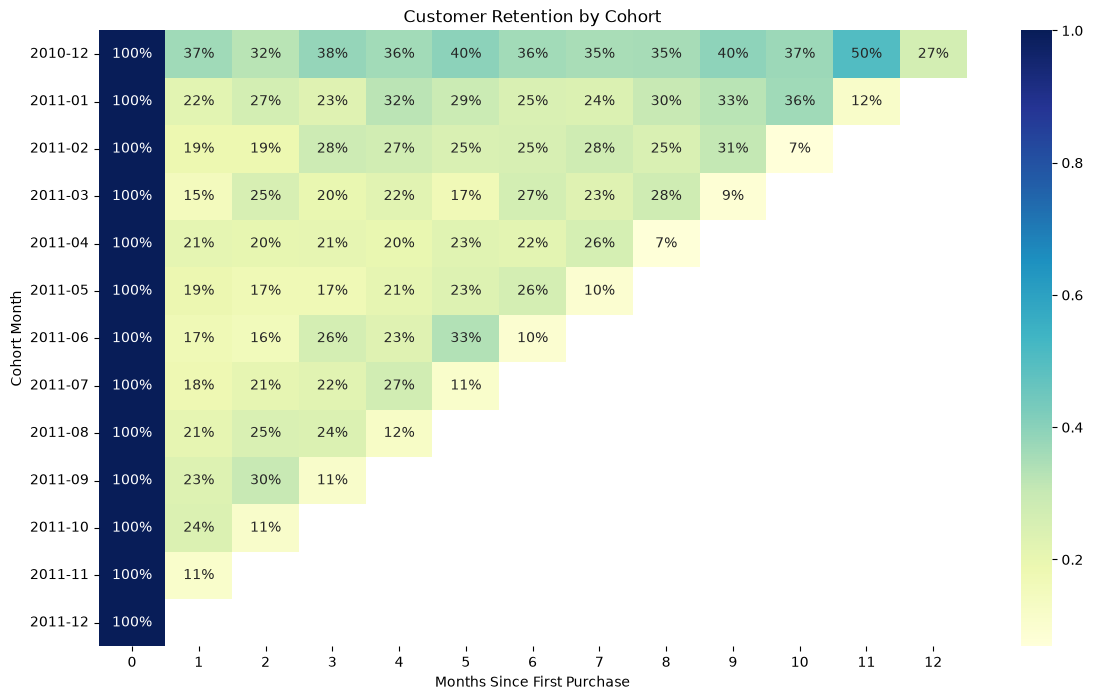

In [30]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    retention,
    annot=True,
    fmt=".0%",
    cmap="YlGnBu"
)

plt.title("Customer Retention by Cohort")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort Month")

plt.show()

Customer retention drops significantly after the first purchase. Most 2011 cohorts retain only around 15–24% of customers in the following month, suggesting that the business has a substantial opportunity to improve repeat purchasing and early customer engagement.

In [31]:
retention.to_csv(
    "../data/processed/retention_matrix.csv"
)